# 01 – Data exploration: UNFAIR-ToS

**Goal of this notebook:** understand the dataset before building any model.

UNFAIR-ToS (LexGLUE) contains sentences from 50 online Terms of Service, annotated by legal experts in the Claudette project.
Each sentence has **zero or more labels** among 8 categories of potentially unfair clauses. A sentence with **no label is fair**.

Questions we answer here:
1. How big is the dataset and how many sentences are unfair? (class imbalance)
2. Which unfairness categories are common and which are rare?
3. Can a sentence belong to more than one category?
4. How long are the sentences? (matters for BERT's 512-token limit and LLM prompts)
5. Are there duplicate sentences, especially between train and test? (data leakage)
6. What do real examples of each category look like?

Run `python scripts/download_data.py` first. Figures are saved in `report/figures/` for the final report.

In [1]:
import json
import textwrap
from collections import Counter
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = PROJECT_ROOT / "data" / "raw"
FIG_DIR = PROJECT_ROOT / "report" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Chart style: one colour per series, thin marks, light grid
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e5e4e0"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "regular",
    "axes.edgecolor": INK_2, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
})

def save(fig, name):
    """Save a figure as PDF (for LaTeX) and PNG (for quick viewing)."""
    for ext in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"{name}.{ext}")

pd.set_option("display.max_colwidth", 120)

## 1. Load the data

In [2]:
metadata = json.loads((RAW_DIR / "metadata.json").read_text(encoding="utf-8"))
LABELS = metadata["label_names"]
SPLITS = ["train", "validation", "test"]

frames = []
for split in SPLITS:
    part = pd.read_json(RAW_DIR / f"unfair_tos_{split}.jsonl", lines=True)
    part["split"] = split
    frames.append(part)
df = pd.concat(frames, ignore_index=True)

df["n_labels"] = df["labels"].apply(len)
df["unfair"] = df["n_labels"] > 0
df["n_words"] = df["text"].str.split().str.len()

print("Label names taken from:", metadata["label_names_source"])
for i, name in enumerate(LABELS):
    print(f"  {i}: {name}")
df.head()

Label names taken from: dataset features
  0: Limitation of liability
  1: Unilateral termination
  2: Unilateral change
  3: Content removal
  4: Contract by using
  5: Choice of law
  6: Jurisdiction
  7: Arbitration


,id,text,labels,label_names,split,n_labels,unfair,n_words
0,train-0,"notice to california subscribers : you may cancel your subscription , without penalty or obligation , at any time pr...",[],[],train,0,False,33
1,train-1,"if you subscribed using your apple id , refunds are handled by apple , not tinder . \n",[],[],train,0,False,17
2,train-2,"if you wish to request a refund , please visit https://getsupport.apple.com . \n",[],[],train,0,False,12
3,train-3,if you subscribed using your google play store account or through tinder online : contact customer support \n,[],[],train,0,False,17
4,train-4,key changes in this version : we 've included a legal notice required under california law regarding refunds and upd...,[],[],train,0,False,28


## 2. Size and class imbalance

How many sentences are in each split, and what share of them is potentially unfair?

In [3]:
overview = df.groupby("split", sort=False).agg(sentences=("text", "size"), unfair=("unfair", "sum"))
overview.loc["total"] = overview.sum()
overview["fair"] = overview["sentences"] - overview["unfair"]
overview["% unfair"] = (100 * overview["unfair"] / overview["sentences"]).round(1)
overview = overview[["sentences", "fair", "unfair", "% unfair"]]
overview

,sentences,fair,unfair,% unfair
split,,,,
train,5532,4902,630,11.4
validation,2275,2045,230,10.1
test,1607,1435,172,10.7
total,9414,8382,1032,11.0


**Why this matters:** if only a small share of sentences is unfair, a model that always answers "fair" gets a high *accuracy* while being useless.
That is why we evaluate with **precision, recall and F1 on the unfair classes**, not accuracy.

## 3. Which categories are common, which are rare?

In [4]:
rows = {}
for split in SPLITS:
    counts = Counter(label for labels in df.loc[df["split"] == split, "labels"] for label in labels)
    rows[split] = [counts.get(i, 0) for i in range(len(LABELS))]

label_counts = pd.DataFrame(rows, index=LABELS)
label_counts["total"] = label_counts.sum(axis=1)
n_unfair_train = int(overview.loc["train", "unfair"])
label_counts["% of unfair (train)"] = (100 * label_counts["train"] / n_unfair_train).round(1)
label_counts = label_counts.sort_values("total", ascending=False)
label_counts

,train,validation,test,total,% of unfair (train)
Limitation of liability,191,67,38,296,30.3
Unilateral termination,139,59,38,236,22.1
Unilateral change,122,28,38,188,19.4
Content removal,73,32,13,118,11.6
Contract by using,76,18,23,117,12.1
Choice of law,39,18,13,70,6.2
Jurisdiction,34,18,16,68,5.4
Arbitration,28,9,7,44,4.4


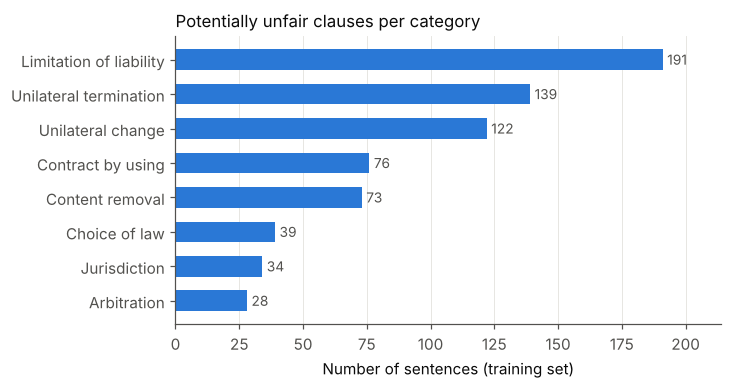

In [5]:
train_counts = label_counts["train"].sort_values()
fig, ax = plt.subplots(figsize=(6.4, 3.4))
bars = ax.barh(train_counts.index, train_counts.values, height=0.6, color=BLUE)
ax.bar_label(bars, padding=3, color=INK_2, fontsize=9)
ax.set_xlabel("Number of sentences (training set)")
ax.set_title("Potentially unfair clauses per category", loc="left")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, train_counts.max() * 1.12)
save(fig, "label_distribution")
plt.show()

**Why this matters:** rare categories have few examples to learn from (for BERT) and few examples to retrieve (for RAG).
We will report **per-category** results, because a good average can hide a category where the system fails.

## 4. Can a sentence have more than one label?

In [6]:
labels_per_unfair_sentence = (
    df.loc[df["unfair"], "n_labels"].value_counts().sort_index().rename("unfair sentences")
)
labels_per_unfair_sentence.index.name = "number of labels"
labels_per_unfair_sentence.to_frame()

,unfair sentences
number of labels,
1,937
2,85
3,10


In [7]:
pair_counts = Counter(
    tuple(sorted((LABELS[a], LABELS[b])))
    for labels in df["labels"] if len(labels) > 1
    for a, b in combinations(sorted(set(labels)), 2)
)
pd.DataFrame(
    [(a, b, n) for (a, b), n in pair_counts.most_common()],
    columns=["category A", "category B", "sentences with both"],
)

,category A,category B,sentences with both
0,Content removal,Unilateral termination,39
1,Unilateral change,Unilateral termination,30
2,Limitation of liability,Unilateral termination,12
3,Content removal,Limitation of liability,8
4,Limitation of liability,Unilateral change,8
5,Content removal,Unilateral change,7
6,Choice of law,Jurisdiction,7
7,Contract by using,Unilateral change,3
8,Choice of law,Contract by using,1


**Why this matters:** this is a **multi-label** problem. The RAG system must be allowed to output more than one category,
and the evaluation must handle sentences with several labels.

## 5. How long are the sentences?

In [8]:
length_stats = df.groupby("unfair")["n_words"].describe(percentiles=[0.5, 0.9, 0.99]).round(1)
length_stats.index = ["fair", "unfair"]
length_stats

,count,mean,std,min,50%,90%,99%,max
fair,8382.0,31.4,23.3,6.0,26.0,57.0,116.2,441.0
unfair,1032.0,43.1,34.9,6.0,33.0,77.0,194.7,353.0


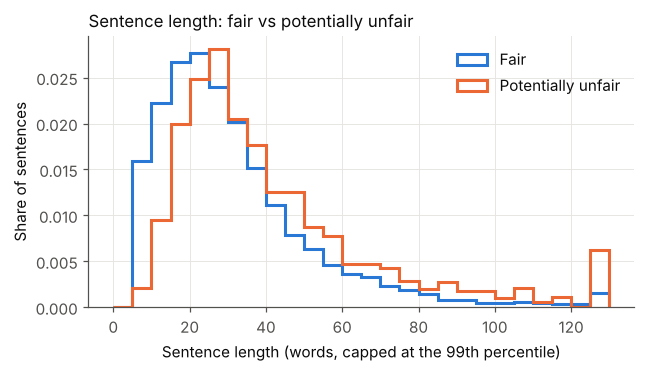

Longest sentence: 441 words
Sentences longer than 300 words: 4


In [9]:
fig, ax = plt.subplots(figsize=(6.4, 3.2))
max_len = int(df["n_words"].quantile(0.99))
bins = range(0, max_len + 5, 5)
ax.hist(df.loc[~df["unfair"], "n_words"].clip(upper=max_len), bins=bins, density=True,
        histtype="step", linewidth=2, color=BLUE, label="Fair")
ax.hist(df.loc[df["unfair"], "n_words"].clip(upper=max_len), bins=bins, density=True,
        histtype="step", linewidth=2, color=ORANGE, label="Potentially unfair")
ax.set_xlabel("Sentence length (words, capped at the 99th percentile)")
ax.set_ylabel("Share of sentences")
ax.set_title("Sentence length: fair vs potentially unfair", loc="left")
ax.legend(frameon=False)
save(fig, "sentence_length")
plt.show()

print("Longest sentence:", df["n_words"].max(), "words")
print("Sentences longer than 300 words:", int((df["n_words"] > 300).sum()))

**Why this matters:** BERT can read at most 512 tokens (roughly 350–400 English words), so very long sentences get cut.
For the LLM, longer sentences mean longer prompts and higher cost.

## 6. Duplicates and data leakage

In [10]:
df["norm_text"] = df["text"].str.lower().str.split().str.join(" ")

dup_within = df[df.duplicated(["split", "norm_text"], keep="first")].groupby("split", sort=False).size()
print("Duplicate sentences inside each split:")
print(dup_within.reindex(SPLITS, fill_value=0).to_string(), "\n")

train_texts = set(df.loc[df["split"] == "train", "norm_text"])
for split in ["validation", "test"]:
    part = df[df["split"] == split]
    leaked = part[part["norm_text"].isin(train_texts)]
    print(f"{split}: {len(leaked)} of {len(part)} sentences also appear in train "
          f"({int(leaked['unfair'].sum())} of them unfair)")

label_sets = df.groupby("norm_text")["labels"].apply(lambda s: {tuple(sorted(x)) for x in s})
inconsistent = label_sets[label_sets.apply(len) > 1]
print("\nSame sentence with different labels:", len(inconsistent))

Duplicate sentences inside each split:
split
train         105
validation     14
test            7 

validation: 18 of 2275 sentences also appear in train (1 of them unfair)
test: 33 of 1607 sentences also appear in train (1 of them unfair)



Same sentence with different labels: 1


**Why this matters:** the RAG knowledge base takes its examples **only from the training set**.
If a test sentence also appears in train, the retriever could find the exact answer, which makes the test too easy.
We must report this, and possibly also evaluate on the test sentences that do not appear in train.

## 7. Examples of each category

In [11]:
train = df[df["split"] == "train"]
for i, name in enumerate(LABELS):
    examples = train[train["labels"].apply(lambda labels: i in labels)]
    print(f"=== {name} ({len(examples)} training sentences) ===")
    for text in examples.sample(min(2, len(examples)), random_state=42)["text"]:
        print(textwrap.fill(text, width=110, initial_indent="  - ", subsequent_indent="    "))
    print()

print("=== Fair (no label) ===")
for text in train[~train["unfair"]].sample(2, random_state=42)["text"]:
    print(textwrap.fill(text, width=110, initial_indent="  - ", subsequent_indent="    "))

=== Limitation of liability (191 training sentences) ===
  - to the extent permissible under applicable law , spotify reserves the right , periodically and at any time
    , to modify or discontinue , temporarily or permanently , functions and features of the spotify service ,
    with or without notice , all without liability to you , except where prohibited by law , for any
    interruption , modification , or discontinuation of the spotify service or any function or feature thereof
    .
  - note that it is your responsibility to be aware of such notices , and you hereby acknowledge and agree
    that blizzard entertainment shall not be responsible for any damages which may arise from your failure to
    read and/or be aware of these publicly posted notices .

=== Unilateral termination (139 training sentences) ===
  - we may suspend , or terminate your access to or use of our services anytime for any reason , such as if
    you violate the letter or spirit of our terms and polices 

## 8. Findings and decisions

**1. Size and splits.** 9,414 sentences: 5,532 train / 2,275 validation / 1,607 test, the same numbers as in the LexGLUE paper (Chalkidis et al., 2022).
The split is **chronological**: training sentences come from ToS versions of 2006–2016, validation and test from 2017. So the test set checks whether a model works on *newer* contracts, which is realistic.
→ *Decision:* we keep the official splits, so our results are comparable with published ones (e.g. Legal-BERT: 96.0 micro-F1 / 83.0 macro-F1 on the test set).

**2. Class imbalance.** Only **11.0%** of sentences are potentially unfair (10.1–11.4% depending on the split). A model answering always "fair" would get 89% accuracy.
→ *Decision:* no accuracy. We report **micro-F1 and macro-F1** with the LexGLUE convention (an extra "fair" label is added during evaluation, "8+1" classes), plus **precision and recall of the binary fair/unfair decision**.
For consumer protection, a missed unfair clause (false negative) is worse than a false alarm, so **recall** deserves special attention. This is an ethical choice, and we will discuss it in the report.

**3. Rare categories.** Limitation of liability is 30% of unfair training sentences, while Arbitration has only 28 training and **7 test** sentences (Jurisdiction 16, Choice of law 13, Content removal 13 in the test set).
→ *Decision:* per-category test scores for rare categories are very noisy (one mistake on 7 examples changes recall by 14 points), so we report the number of examples next to each score and avoid over-interpreting small differences.
For the RAG system, rare categories have few examples to retrieve, so **definitions and legal rationales** in the knowledge base matter most there.

**4. Multi-label.** 95 of 1,032 unfair sentences (9.2%) have 2 or 3 labels. The most common pairs are Content removal + Unilateral termination (39) and Unilateral change + Unilateral termination (30): clauses like "we may delete your content and terminate your account at any time".
→ *Decision:* the RAG output must be a **list** of categories, and the prompt must allow more than one.

**5. Sentence length.** Unfair sentences are longer (median 33 words vs 26). 99% of sentences are below ~195 words and only 4 exceed 300 words.
→ *Decision:* BERT's 512-token limit is not a practical problem, and single-sentence LLM prompts stay short and cheap.

**6. Text format.** All sentences are **lowercased and tokenized** (spaces before punctuation, e.g. `terms .`).
→ *Decision:* use uncased models or keep this in mind for the LLM; in the demo, real user text (normal casing) should be normalised the same way, otherwise the input differs from what the system was built on.

**7. Duplicates and leakage.** 33 test sentences (2.1%) also appear in train, but only **1** of them is unfair; 171 of the 172 unfair test sentences are new. One sentence has inconsistent labels (*"if you repeatedly infringe other people's intellectual property rights, we will disable your account when appropriate"* is once fair, once Unilateral termination), a sign that fair vs unfair is sometimes a judgement call even for experts.
→ *Decision:* leakage is negligible for unfair clauses, so we keep the test set as it is. The knowledge base will use **training sentences only**.

**8. What the dataset does *not* contain.** Only category labels: no "potentially" vs "clearly" unfair level, no written explanations or legal rationales, no "privacy included" category, and only English.
→ *Decision:* explanation quality cannot be measured automatically against gold explanations: we will evaluate it on a manually checked sample, using rationales we write for the knowledge base. The multilingual extension needs translated data.